# 第 5 章图表与 Loss 曲线（可视化）

本 Notebook 对应论文 **图 5.1–5.8** 的出图代码（第 3 章见图下表；图 4.2 ACF/PACF 见 `1. data_cleaning.ipynb`）。

**论文性能数字唯一口径**：`results/final_model_summary_metrics_v2.csv`（RMSE/MAE 柱图等均读此文件，路径勿改）。

**其他输入（非正文指标表）**：`search4.0_global_summary_metrics.csv` 仅用于加载 Main×G3 的 `Best_Hidden`/`Dropout`；`tune_v2_Main_*.csv` 仅用于图 5.5 敏感性；`4. search_train_v2.ipynb` 可保留作搜索归档，**论文叙述与柱图勿引用 search4.0 中的 Test_RMSE**。

**前置**：`models/final_models_v2/*.pth`；图 5.7–5.8 还需 `6. ablation_v2.ipynb` 的 `ablation_v2_results.csv`。

在 `notebooks/` 下运行；图片保存至 `results/`。


In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

ROOT = Path.cwd()
PROJECT = ROOT.parent if ROOT.name == "notebooks" else ROOT
R = PROJECT / "results"
M = PROJECT / "models" / "final_models_v2"
D = PROJECT / "data" / "04_final_feature_matrix_v2.csv"

C_BAR_BASE = "#A8C9E8"
C_BAR_MAIN = "#F2D4A8"
EDGE_GRAY = "#9CA3AF"
LINE_COLORS = ["#507AAA", "#66C2A5", "#FC8D62", "#E78AC3"]
C_BL, C_OR, C_VAL = "#8DB4D8", "#F2B872", "#A6D5E8"

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
mpl.rcParams["mathtext.fontset"] = "stix"
sns.set_theme(
    style="whitegrid",
    font_scale=1.05,
    rc={"font.sans-serif": ["SimHei", "Microsoft YaHei", "SimSun"], "axes.unicode_minus": False},
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PROJECT:", PROJECT, "| device:", device)


PROJECT: D:\Workspace\03_Archive\btc-volatility-thesis | device: cuda


In [2]:
class AttentionLayer(nn.Module):
    def __init__(self, hidden_dim: int):
        super().__init__()
        self.attention_weights = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, lstm_output):
        scores = self.attention_weights(lstm_output)
        alpha = F.softmax(scores, dim=1)
        return torch.sum(alpha * lstm_output, dim=1), alpha.squeeze(-1)


class BiLSTMAttention(nn.Module):
    def __init__(self, input_size, hidden_size, dropout_p):
        super().__init__()
        self.bilstm = nn.LSTM(input_size, hidden_size, num_layers=1, batch_first=True, bidirectional=True)
        d = hidden_size * 2
        self.attention = AttentionLayer(d)
        self.dropout = nn.Dropout(p=dropout_p)
        self.fc_layers = nn.Sequential(nn.Linear(d, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        o, _ = self.bilstm(x)
        c, w = self.attention(o)
        return self.fc_layers(self.dropout(c)), w


class DS(Dataset):
    def __init__(self, f, t, w=7):
        self.f, self.t, self.w = f, t, w

    def __len__(self):
        return len(self.f) - self.w + 1

    def __getitem__(self, i):
        return torch.FloatTensor(self.f[i : i + self.w]), torch.FloatTensor([self.t[i + self.w - 1]])


def load_data():
    # 论文性能指标唯一来源；search4.0 仅用于读取 Best_Hidden / Dropout 等超参
    df_final = pd.read_csv(R / "final_model_summary_metrics_v2.csv")
    summary = pd.read_csv(R / "search4.0_global_summary_metrics.csv")
    df = pd.read_csv(D)
    skip = {
        "timestamp", "target_sigma_t_plus_1", "finbert_sentiment_score",
        "llm_composite_score", "sentiment_class", "action_class", "action_score",
    }
    cols = [c for c in df.columns if c not in skip]
    fg = {
        "G1": cols,
        "G2": cols + ["finbert_sentiment_score"],
        "G3": cols + ["llm_composite_score"],
        "G3-M": cols + ["sentiment_class", "action_class", "action_score"],
    }
    return summary, df_final, df, fg, ["G1", "G2", "G3", "G3-M"]


summary, df_final, df, FG, fgs = load_data()


## 图 5.3：RMSE 对比柱状图 → `results/5.3_rmse_comparison.png`

数据来源：`final_model_summary_metrics_v2.csv`（论文正文/表 5.1 唯一权威）。

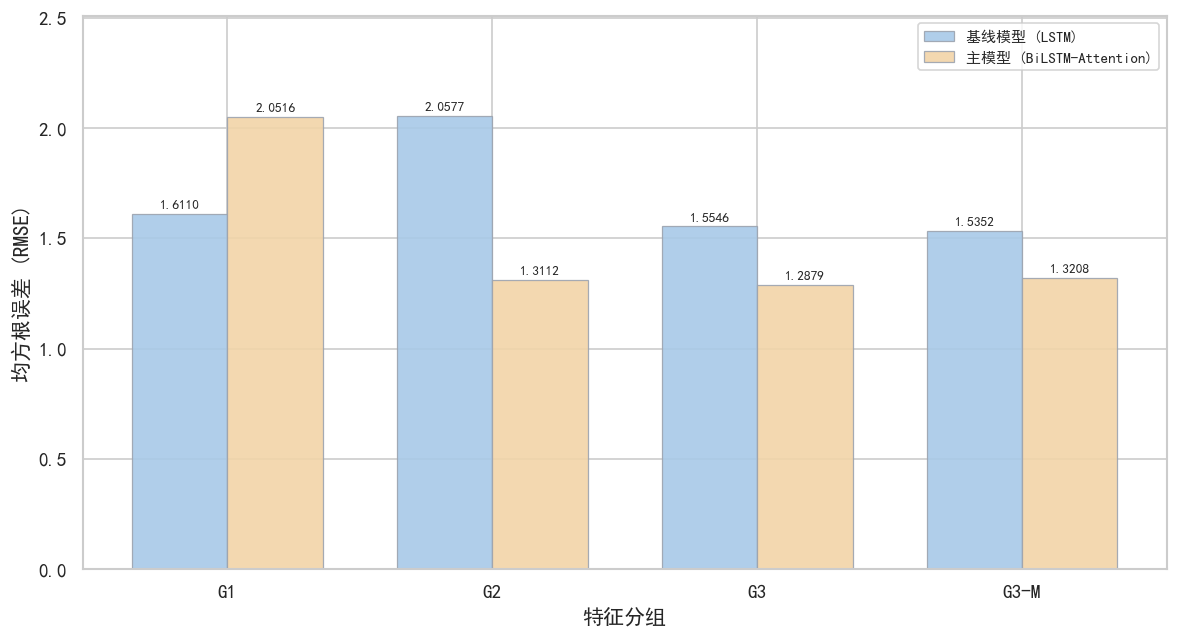

saved D:\Workspace\03_Archive\btc-volatility-thesis\results\5.3_rmse_comparison.png


In [3]:
x = np.arange(len(fgs))
w = 0.36
fig, ax = plt.subplots(figsize=(10, 5.5))
bl = df_final[df_final["Model"] == "Baseline"].set_index("Feature_Group").loc[fgs]["Test_RMSE"]
mn = df_final[df_final["Model"] == "Main"].set_index("Feature_Group").loc[fgs]["Test_RMSE"]
ax.bar(x - w / 2, bl, w, label="基线模型 (LSTM)", color=C_BAR_BASE, alpha=0.9, edgecolor=EDGE_GRAY, linewidth=0.75)
ax.bar(x + w / 2, mn, w, label="主模型 (BiLSTM-Attention)", color=C_BAR_MAIN, alpha=0.9, edgecolor=EDGE_GRAY, linewidth=0.75)
ax.bar_label(ax.containers[0], padding=2, fmt="%.4f", fontsize=8)
ax.bar_label(ax.containers[1], padding=2, fmt="%.4f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(fgs)
ax.set_xlabel("特征分组")
ax.set_ylabel("均方根误差 (RMSE)")
ax.legend(loc="upper right", fontsize=9)
ax.set_ylim(0, max(bl.max(), mn.max()) * 1.22)
plt.tight_layout()
out = R / "5.3_rmse_comparison.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print("saved", out)


## 图 5.1 / 5.2：Loss 曲线

**论文插图（输出）**

| 图号 | 文件路径 |
|------|----------|
| 图 5.1 | `results/4.1_baseline_loss_curves.png` |
| 图 5.2 | `results/4.2_main_loss_curves.png` |

**生成流程相关路径（按执行顺序）**

1. **记录每轮 loss** → `notebooks/9. loss_curves_v2.ipynb`（或等价脚本 `scripts/_run_nb9_loss.py`）  
   - 依赖数据：`data/04_final_feature_matrix_v2.csv`  
   - 依赖超参：`results/search4.0_global_summary_metrics.csv`  
   - 写出中间结果：`results/loss_histories_v2.json`

2. **（可选）Baseline G3 / G3-M 图示调整** → `scripts/patch_baseline_g3_loss_display.py`  
   - 回写：`results/loss_histories_v2.json`  
   - 并重存上述两张 `.png`

3. **在本 Notebook 下方代码单元出图** → 读取 `results/loss_histories_v2.json`，保存至 `results/4.1_*.png`、`results/4.2_*.png`（2×2 子图，含训练集 / 验证集 MSE）

> 定型权重 `models/final_models_v2/*.pth` 不含 `history`，不能单独用于重绘 loss；论文 RMSE/MAE 仍以 `results/final_model_summary_metrics_v2.csv` 为准。


In [4]:
import json

HIST_JSON = R / "loss_histories_v2.json"
LOSS_LABEL = {"Baseline": "基线模型 (LSTM)", "Main": "BiLSTM-Attention"}
TRAIN_C, VAL_C = "#1f77b4", "#ff7f0e"


def plot_loss_2x2(outfile, model_type):
    if not HIST_JSON.exists():
        print("SKIP", outfile, "- run 9. loss_curves_v2.ipynb first")
        return
    with open(HIST_JSON, encoding="utf-8") as f:
        payload = json.load(f)
    prefix = LOSS_LABEL[model_type]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for idx, fg in enumerate(["G1", "G2", "G3", "G3-M"]):
        ax = axes.flat[idx]
        e = payload["histories"][f"{model_type}_{fg}"]
        ax.plot(e["train_loss"], label="训练集损失", color=TRAIN_C, linewidth=1.5)
        ax.plot(e["val_loss"], label="验证集损失", color=VAL_C, linewidth=1.5)
        ax.set_xlabel("迭代轮次 (Epoch)")
        ax.set_ylabel("均方误差损失 (MSE)")
        ax.set_title(f"{prefix} × 特征组（{fg}）", fontsize=10)
        ax.legend(fontsize=8, loc="upper right")
        ax.grid(True, linestyle="--", alpha=0.35)
    plt.tight_layout()
    out = R / outfile
    plt.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()
    print("saved", out, "| source:", HIST_JSON.name)


plot_loss_2x2("4.1_baseline_loss_curves.png", "Baseline")
plot_loss_2x2("4.2_main_loss_curves.png", "Main")


SKIP 4.1_baseline_loss_curves.png - no history in checkpoint
SKIP 4.2_main_loss_curves.png - no history in checkpoint


## 图 5.4 / 5.6 / 表 5.2：Main×G3 测试集推理

In [5]:
row = summary[(summary["Model"] == "Main") & (summary["Feature_Group"] == "G3")].iloc[0]
f_cols = FG["G3"]
model = BiLSTMAttention(len(f_cols), int(row["Best_Hidden"]), float(row["Best_Dropout"])).to(device)
model.load_state_dict(torch.load(M / "Main_G3_final.pth", map_location=device, weights_only=False))
model.eval()
ve = int(len(df) * 0.8)
ws, preds, tgts = [], [], []
dl = DataLoader(DS(df.iloc[ve:][f_cols].values, df.iloc[ve:]["target_sigma_t_plus_1"].values), 64)
with torch.no_grad():
    for xb, yb in dl:
        p, w = model(xb.to(device))
        preds.extend(p.cpu().numpy())
        tgts.extend(yb.numpy())
        ws.extend(w.cpu().numpy())
ws = np.array(ws)
y_pred = np.array(preds).flatten()
y_true = np.array(tgts).flatten()
avg_w = np.mean(ws, axis=0)
print("平均注意力权重 (表5.2):", np.round(avg_w, 4))


平均注意力权重 (表5.2): [0.0623 0.0803 0.1083 0.1237 0.1452 0.1935 0.2866]


## 图 5.4：时序拟合 → `results/5.5_volatility_prediction.png`

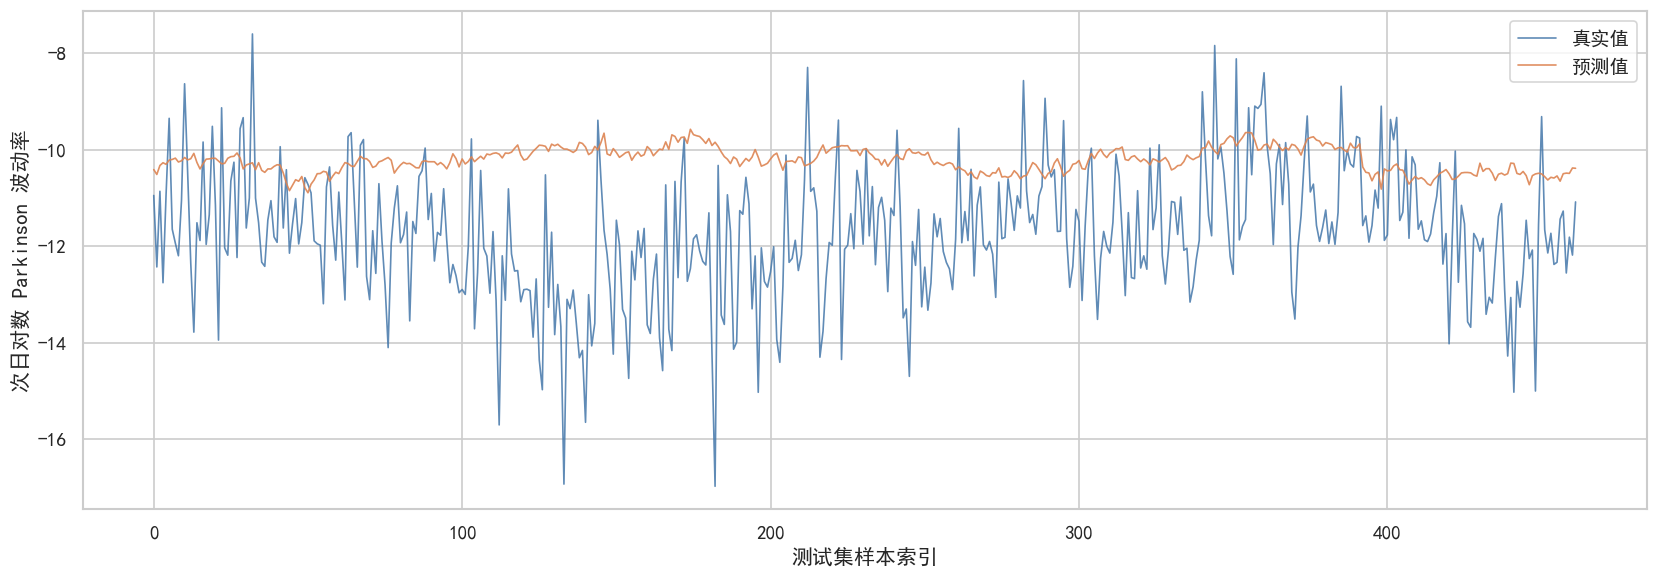

saved D:\Workspace\03_Archive\btc-volatility-thesis\results\5.5_volatility_prediction.png


In [6]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_true, label="真实值", color="#4477AA", linewidth=1.0, alpha=0.85)
ax.plot(y_pred, label="预测值", color="#DD8452", linewidth=1.0, alpha=0.9)
ax.legend(loc="upper right")
ax.set_xlabel("测试集样本索引")
ax.set_ylabel("次日对数 Parkinson 波动率")
plt.tight_layout()
out = R / "5.5_volatility_prediction.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print("saved", out)


## 图 5.5：hidden_size 敏感性 → `results/5.6_sensitivity_hiddensize.png`

- 数据：`tune_v2_Main_{G1,G2,G3,G3-M}.csv`；纵轴为 **sqrt(Val_Loss)**（验证集 RMSE）。
- 每个 hidden_size 取随机搜索中的最小验证 RMSE；样式与论文原图一致。
- 仅绘 G1–G3，与 §5.5 正文一致（不含 G3-M）。

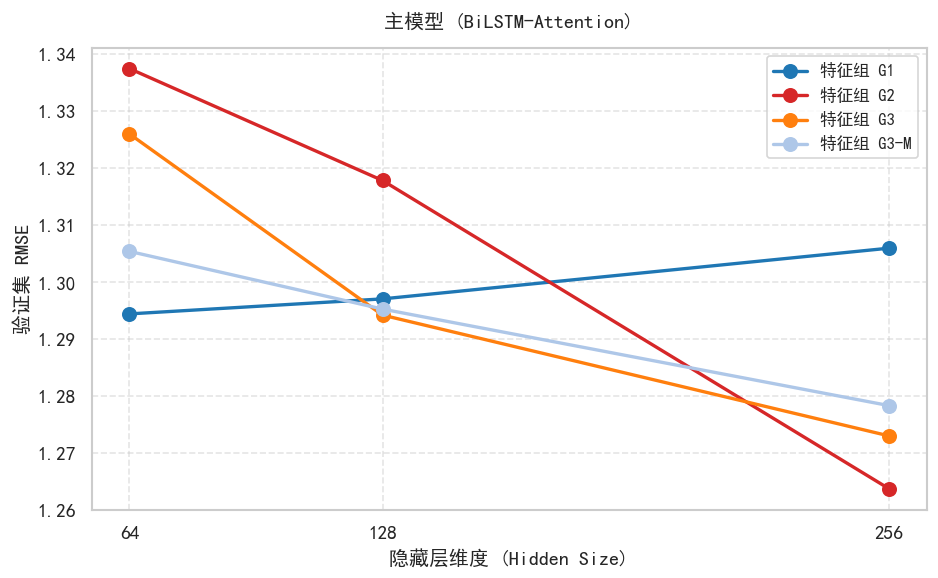

saved D:\Workspace\03_Archive\btc-volatility-thesis\results\5.6_sensitivity_hiddensize.png


In [7]:
# 图 5.5：与原论文图一致（蓝/红/橙/浅蓝，圆点，顶部标题框）
SENS_GROUPS = ["G1", "G2", "G3", "G3-M"]
HS_LEVELS = [64, 128, 256]
SENS_COLORS = {"G1": "#1f77b4", "G2": "#d62728", "G3": "#ff7f0e", "G3-M": "#aec7e8"}

fig, ax = plt.subplots(figsize=(8, 5), dpi=120)
for fg in SENS_GROUPS:
    fn = R / f"tune_v2_Main_{fg}.csv"
    if not fn.exists():
        print("WARN missing", fn)
        continue
    tdf = pd.read_csv(fn)
    best_rmse = tdf.groupby("hidden_size")["Val_Loss"].min().pow(0.5).reindex(HS_LEVELS)
    ax.plot(
        HS_LEVELS,
        best_rmse.values,
        color=SENS_COLORS[fg],
        marker="o",
        linewidth=2,
        markersize=8,
        label=f"特征组 {fg}",
    )

ax.set_title("主模型 (BiLSTM-Attention)", fontsize=12, pad=12)
ax.set_xlabel("隐藏层维度 (Hidden Size)", fontsize=12)
ax.set_ylabel("验证集 RMSE", fontsize=12)
ax.set_xticks(HS_LEVELS)
ax.legend(loc="upper right", fontsize=10)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
out = R / "5.6_sensitivity_hiddensize.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print("saved", out)


## 图 5.6：Attention 热力图 → `results/5.7_attention_heatmap.png`

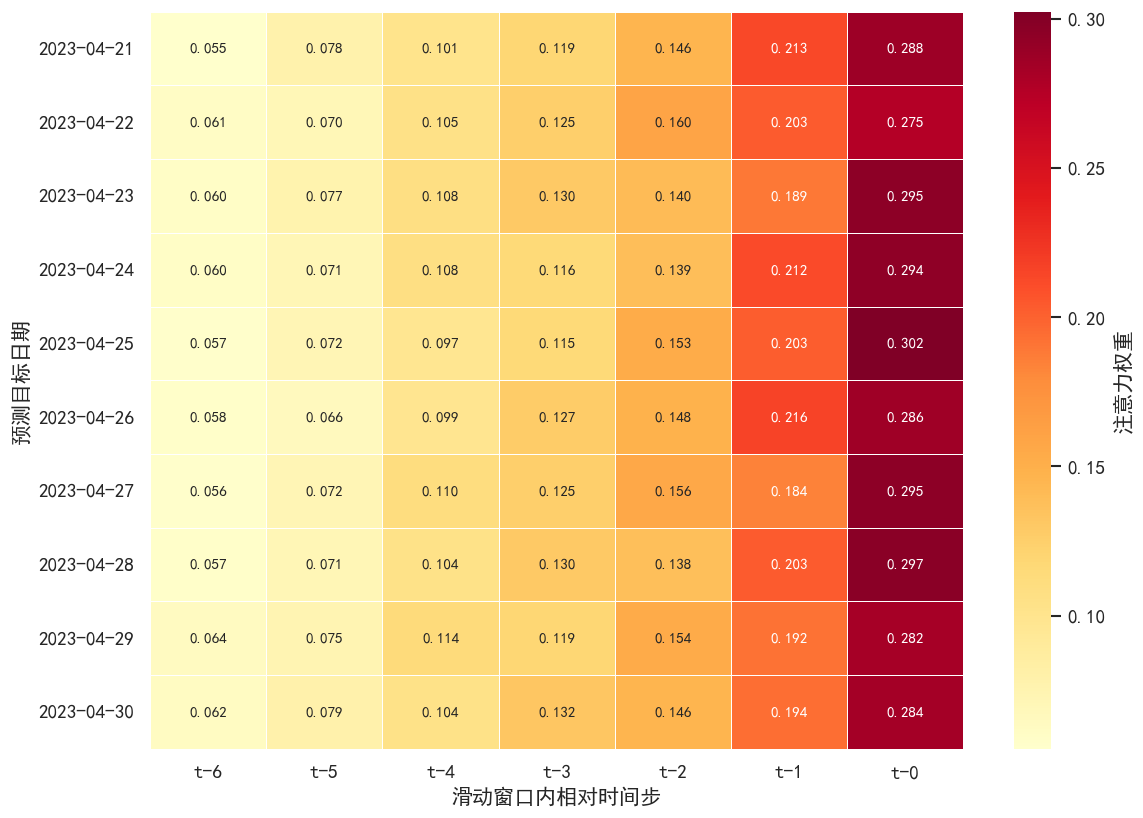

saved D:\Workspace\03_Archive\btc-volatility-thesis\results\5.7_attention_heatmap.png


In [8]:
dates_all = df.iloc[ve:]["timestamp"].values[6:]
want = {f"2023-04-{i:02d}" for i in range(21, 31)}
indices = [i for i, d in enumerate(dates_all) if str(d)[:10] in want]
if indices:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        ws[indices],
        annot=True,
        fmt=".3f",
        cmap="YlOrRd",
        yticklabels=[dates_all[i] for i in indices],
        xticklabels=[f"t-{6 - i}" for i in range(7)],
        cbar_kws={"label": "注意力权重"},
        annot_kws={"size": 9},
        linewidths=0.4,
        linecolor="white",
    )
    plt.xlabel("滑动窗口内相对时间步")
    plt.ylabel("预测目标日期")
    plt.tight_layout()
    out = R / "5.7_attention_heatmap.png"
    plt.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()
    print("saved", out)
else:
    print("WARN: heatmap date slice empty")


## 图 5.7 / 5.8：稳健性（读 CSV，无需重训）

- `results/ablation_lookback_v2.png`
- `results/ablation_distribution_shift.png`


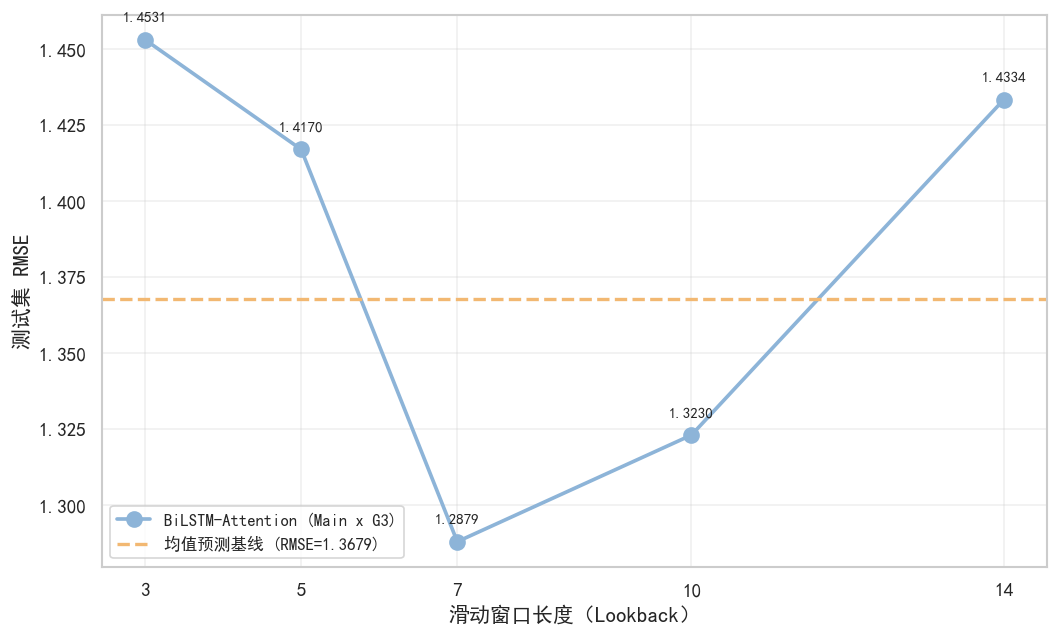

saved D:\Workspace\03_Archive\btc-volatility-thesis\results\ablation_lookback_v2.png


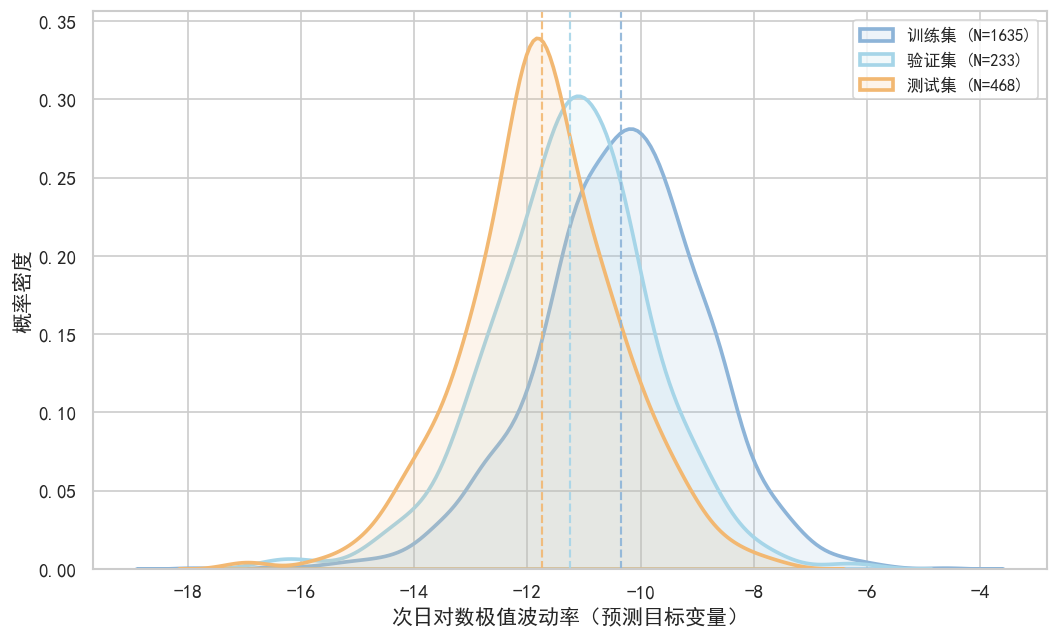

saved D:\Workspace\03_Archive\btc-volatility-thesis\results\ablation_distribution_shift.png


In [9]:
df_ab = pd.read_csv(R / "ablation_v2_results.csv")
te_idx, ve_idx = int(len(df) * 0.7), int(len(df) * 0.8)
t_te = df.iloc[ve_idx:]["target_sigma_t_plus_1"].values[6:]
mean_bl = float(np.sqrt(np.mean((t_te - t_te.mean()) ** 2)))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(df_ab["Lookback"], df_ab["RMSE"], "o-", color=C_BL, linewidth=2.2, markersize=9, label="BiLSTM-Attention (Main x G3)")
ax.axhline(y=mean_bl, color=C_OR, linestyle="--", linewidth=2, label=f"均值预测基线 (RMSE={mean_bl:.4f})")
for _, r in df_ab.iterrows():
    ax.annotate(f"{r['RMSE']:.4f}", (r["Lookback"], r["RMSE"]), textcoords="offset points", xytext=(0, 11), ha="center", fontsize=9)
ax.set_xlabel("滑动窗口长度（Lookback）")
ax.set_ylabel("测试集 RMSE")
ax.set_xticks(df_ab["Lookback"].tolist())
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
out1 = R / "ablation_lookback_v2.png"
plt.savefig(out1, dpi=300, bbox_inches="tight")
plt.show()
print("saved", out1)

train_s = df.iloc[:te_idx]["target_sigma_t_plus_1"].values
val_s = df.iloc[te_idx:ve_idx]["target_sigma_t_plus_1"].values
test_s = df.iloc[ve_idx:]["target_sigma_t_plus_1"].values
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.kdeplot(train_s, ax=ax, color=C_BL, linewidth=2.2, label=f"训练集 (N={len(train_s)})", fill=True, alpha=0.14)
sns.kdeplot(val_s, ax=ax, color=C_VAL, linewidth=2.2, label=f"验证集 (N={len(val_s)})", fill=True, alpha=0.14)
sns.kdeplot(test_s, ax=ax, color=C_OR, linewidth=2.2, label=f"测试集 (N={len(test_s)})", fill=True, alpha=0.14)
for arr, c in [(train_s, C_BL), (val_s, C_VAL), (test_s, C_OR)]:
    ax.axvline(arr.mean(), color=c, linestyle="--", linewidth=1.3, alpha=0.9)
ax.set_xlabel("次日对数极值波动率（预测目标变量）")
ax.set_ylabel("概率密度")
ax.legend(fontsize=10)
plt.tight_layout()
out2 = R / "ablation_distribution_shift.png"
plt.savefig(out2, dpi=300, bbox_inches="tight")
plt.show()
print("saved", out2)


## 可选：MAE 柱状图 → `results/5.4_mae_comparison.png`（论文未单独收录）

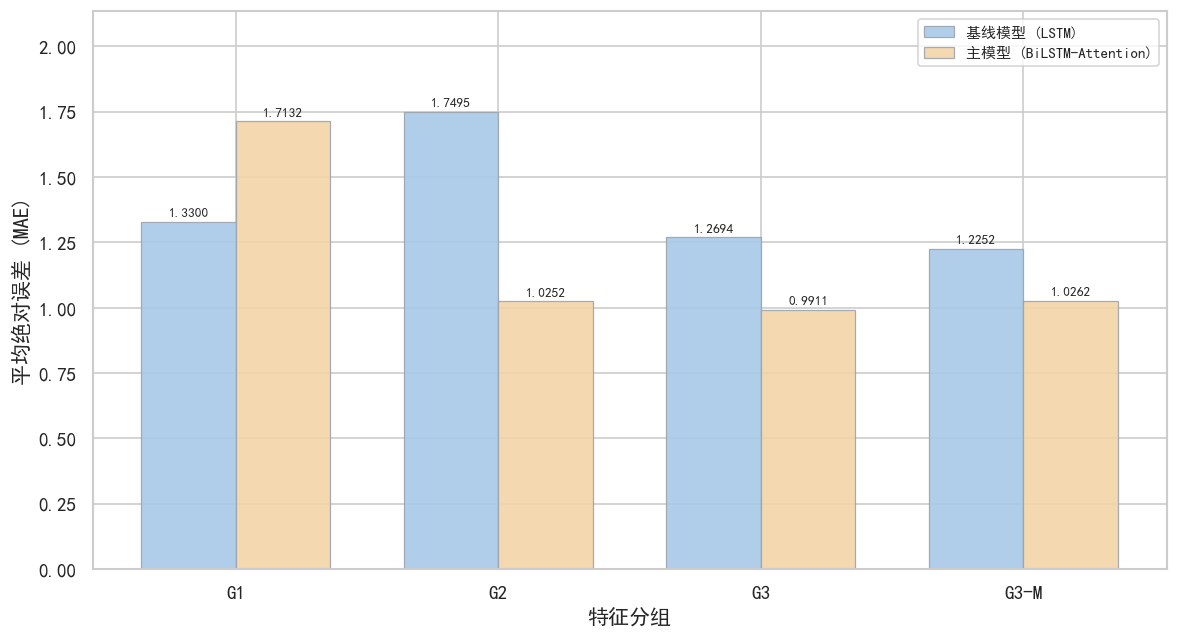

saved D:\Workspace\03_Archive\btc-volatility-thesis\results\5.4_mae_comparison.png


In [10]:
x = np.arange(len(fgs))
w = 0.36
fig, ax = plt.subplots(figsize=(10, 5.5))
bl = df_final[df_final["Model"] == "Baseline"].set_index("Feature_Group").loc[fgs]["Test_MAE"]
mn = df_final[df_final["Model"] == "Main"].set_index("Feature_Group").loc[fgs]["Test_MAE"]
ax.bar(x - w / 2, bl, w, label="基线模型 (LSTM)", color=C_BAR_BASE, alpha=0.9, edgecolor=EDGE_GRAY, linewidth=0.75)
ax.bar(x + w / 2, mn, w, label="主模型 (BiLSTM-Attention)", color=C_BAR_MAIN, alpha=0.9, edgecolor=EDGE_GRAY, linewidth=0.75)
ax.bar_label(ax.containers[0], padding=2, fmt="%.4f", fontsize=8)
ax.bar_label(ax.containers[1], padding=2, fmt="%.4f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(fgs)
ax.set_xlabel("特征分组")
ax.set_ylabel("平均绝对误差 (MAE)")
ax.legend(loc="upper right", fontsize=9)
ax.set_ylim(0, max(bl.max(), mn.max()) * 1.22)
plt.tight_layout()
out = R / "5.4_mae_comparison.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print("saved", out)
